# 03 · Informe: datos y gráficas

Este notebook calcula **todo lo que aparece en el informe** (`docs/informe/Informe_SplitSteal.docx`):
cada tabla, cada cifra y cada gráfica. Así el informe y los datos nunca se contradicen.

- Las gráficas se guardan en `docs/informe/figs/`.
- Las cifras clave se guardan en `docs/informe/cifras.json`, que lee el script que monta el Word
  (`python docs/informe/build_informe.py`).

Fuentes: los experimentos versionados (`results/experiments/*/summary.csv`, 50 semillas por
condición), el run canónico (`results/canonical/`) y algunas simulaciones que se hacen aquí
mismo (parejas con ruido, desempates con varias semillas y evolución). Tarda alrededor de un minuto.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from split_steal import plots
from split_steal.plots import (SERIES, SURFACE, INK, INK_2, GRID, BLUE, OTHERS_COLOR,
                               _save, _subtitle, _percent_axis)
from split_steal.register import PRESETS, make_strategy
from split_steal.runner import TournamentConfig, load_run
from split_steal.simulator import play_match
from split_steal.multiseed import run_seeds
from split_steal.evolution import EvolutionConfig, payoff_matrix, evolve

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 2)

ROOT = Path("..")
EXP = ROOT / "results" / "experiments"
FIGS = ROOT / "docs" / "informe" / "figs"
FIGS.mkdir(parents=True, exist_ok=True)
CIFRAS = {}                      # cifras clave para el texto del informe

def guardar(fig, nombre):
    """Guarda la figura para el informe y la deja visible en el notebook."""
    _save(fig, FIGS / f"{nombre}.png")
    display(fig)

def grupo(nombre):
    tags = make_strategy(nombre).tags
    return "Amable" if "amable" in tags else ("Traicionera" if "traicionera" in tags else "Otra")

# Colores por tipo de estrategia (paleta categórica en orden fijo; gris para "Otra")
COLOR_GRUPO = {"Amable": SERIES[0], "Traicionera": SERIES[1], "Otra": OTHERS_COLOR}
summ = {n: pd.read_csv(EXP / n / "summary.csv")
        for n in ["ruido", "perdon_optimo", "formatos", "tentacion", "entornos"]}
canon = load_run(ROOT / "results" / "canonical")

## 1. Las 36 personalidades

Mapa de etiquetas: qué rasgos tiene cada estrategia del roster oficial.

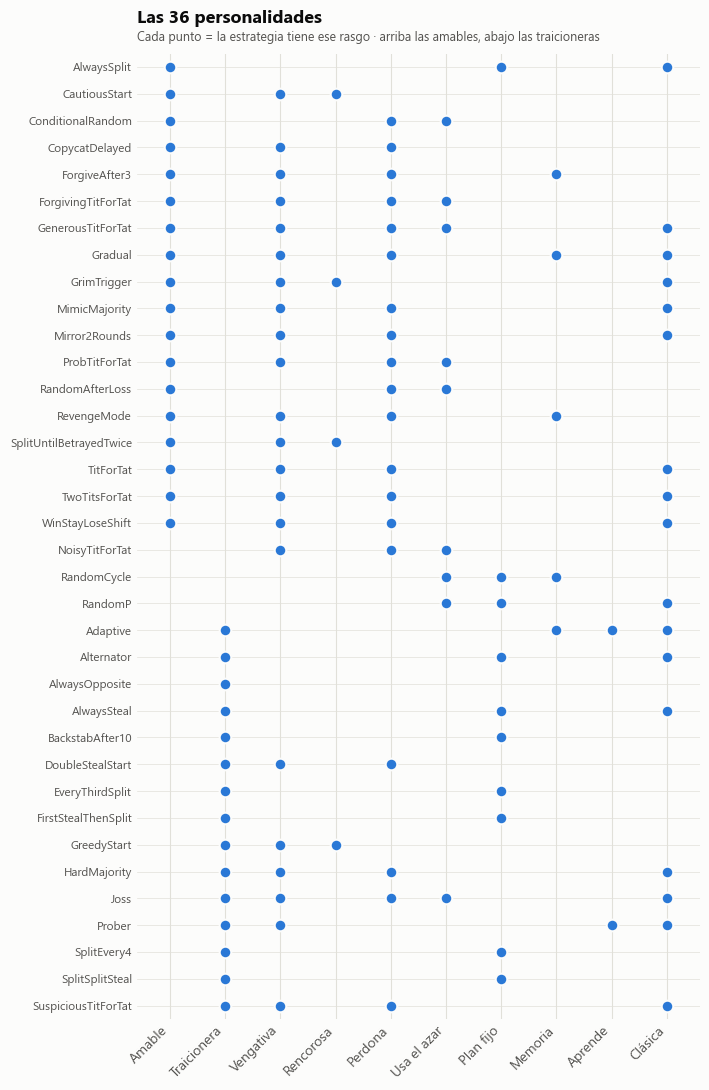

In [2]:
TAG_ORDER = ["amable", "traicionera", "vengativa", "rencorosa", "perdona", "aleatoria",
             "fija", "con_memoria", "adaptativa", "clasica"]
TAG_LABEL = {"amable": "Amable", "traicionera": "Traicionera", "vengativa": "Vengativa",
             "rencorosa": "Rencorosa", "perdona": "Perdona", "aleatoria": "Usa el azar",
             "fija": "Plan fijo", "con_memoria": "Memoria", "adaptativa": "Aprende",
             "clasica": "Clásica"}
names = PRESETS["full"]
order = sorted(names, key=lambda n: (["Amable", "Otra", "Traicionera"].index(grupo(n)), n))
grid = pd.DataFrame([[t in make_strategy(n).tags for t in TAG_ORDER] for n in order],
                    index=order, columns=TAG_ORDER)

fig, ax = plt.subplots(figsize=(7.2, 11))
ys, xs = np.nonzero(grid.values)
ax.scatter(xs, ys, s=70, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.set_xticks(range(len(TAG_ORDER)), [TAG_LABEL[t] for t in TAG_ORDER], rotation=45, ha="right")
ax.set_yticks(range(len(order)), order, fontsize=8.5)
ax.set_xlim(-0.6, len(TAG_ORDER) - 0.4); ax.set_ylim(len(order) - 0.5, -0.5)
for x in range(len(TAG_ORDER)):
    ax.axvline(x, color=GRID, linewidth=0.8, zorder=1)
for y in range(len(order)):
    ax.axhline(y, color=GRID, linewidth=0.5, zorder=1)
for s in ax.spines.values(): s.set_visible(False)
ax.tick_params(length=0)
ax.set_title("Las 36 personalidades", pad=22)
_subtitle(ax, "Cada punto = la estrategia tiene ese rasgo · arriba las amables, abajo las traicioneras")
fig.tight_layout()
guardar(fig, "f01_personalidades")
CIFRAS["n_amables"] = len(PRESETS["amables"]); CIFRAS["n_traicioneras"] = len(PRESETS["traicioneras"])

## 2. ¿Quién gana? (formato canónico, sin ruido, 50 semillas)

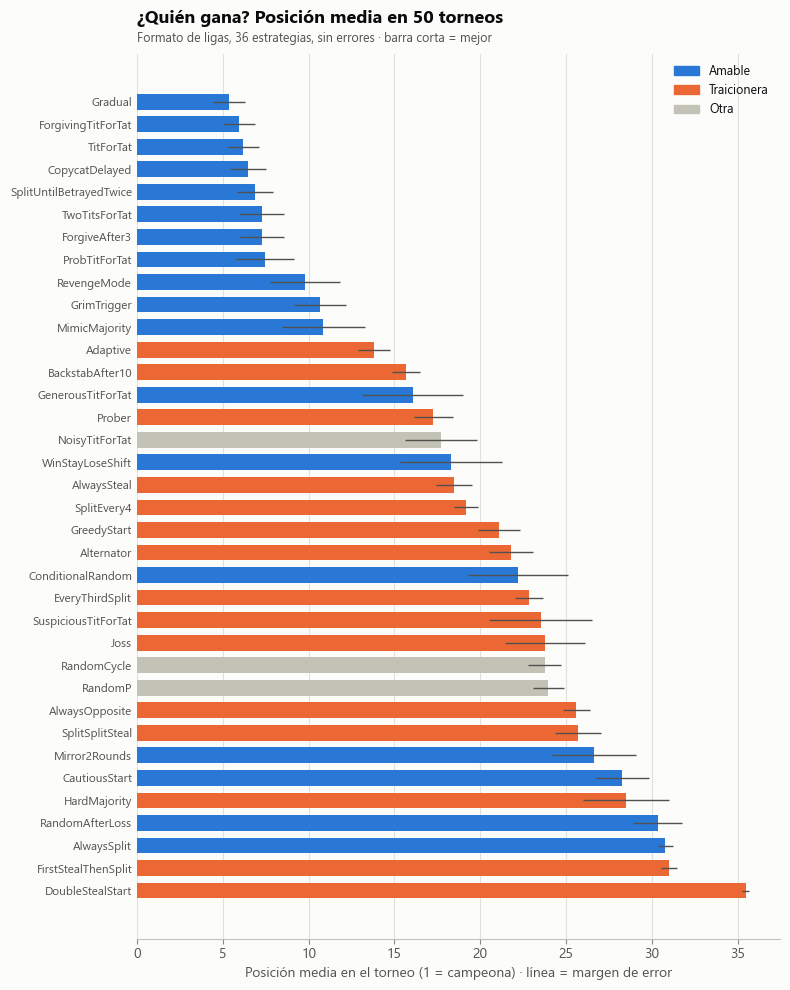

,strategy,grupo,rank_mean,rank_ci95,title_rate,league1_rate,coop_rate
0,Gradual,Amable,5.38,0.94,0.10,0.64,0.90
1,ForgivingTitForTat,Amable,5.94,0.95,0.08,0.61,0.91
2,TitForTat,Amable,6.20,0.93,0.06,0.55,0.89
3,CopycatDelayed,Amable,6.46,1.06,0.10,0.56,0.89
4,SplitUntilBetrayedTwice,Amable,6.88,1.06,0.10,0.47,0.79
5,TwoTitsForTat,Amable,7.26,1.29,0.14,0.43,0.76
6,ForgiveAfter3,Amable,7.28,1.28,0.08,0.45,0.77
7,ProbTitForTat,Amable,7.44,1.74,0.10,0.55,0.91
8,RevengeMode,Amable,9.78,2.03,0.06,0.22,0.77
9,GrimTrigger,Amable,10.66,1.51,0.02,0.32,0.66


In [3]:
r0 = summ["ruido"][summ["ruido"].noise == 0].copy()
r0["grupo"] = r0.strategy.map(grupo)
r0 = r0.sort_values("rank_mean")

fig, ax = plt.subplots(figsize=(8, 10))
y = np.arange(len(r0))
ax.barh(y, r0.rank_mean, xerr=r0.rank_ci95, height=0.7,
        color=[COLOR_GRUPO[g] for g in r0.grupo], error_kw=dict(ecolor=INK_2, lw=1, capsize=0))
ax.set_yticks(y, r0.strategy, fontsize=8.5); ax.invert_yaxis()
ax.set_xlabel("Posición media en el torneo (1 = campeona) · línea = margen de error")
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
# Leyenda con muestras de color explícitas (una barra vacía no conserva su color)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=g) for g, c in COLOR_GRUPO.items()],
          frameon=False, loc="upper right", fontsize=9)
ax.set_title("¿Quién gana? Posición media en 50 torneos", pad=22)
_subtitle(ax, "Formato de ligas, 36 estrategias, sin errores · barra corta = mejor")
fig.tight_layout(); guardar(fig, "f03_quien_gana")

CIFRAS["top5_sin_ruido"] = r0.strategy.head(5).tolist()
CIFRAS["top10_amables"] = int((r0.head(10).grupo == "Amable").sum())
CIFRAS["bottom10_traicioneras"] = int((r0.tail(10).grupo == "Traicionera").sum())
CIFRAS["rank_medio_grupo"] = r0.groupby("grupo").rank_mean.mean().round(1).to_dict()
r0[["strategy", "grupo", "rank_mean", "rank_ci95", "title_rate", "league1_rate", "coop_rate"]].head(12)

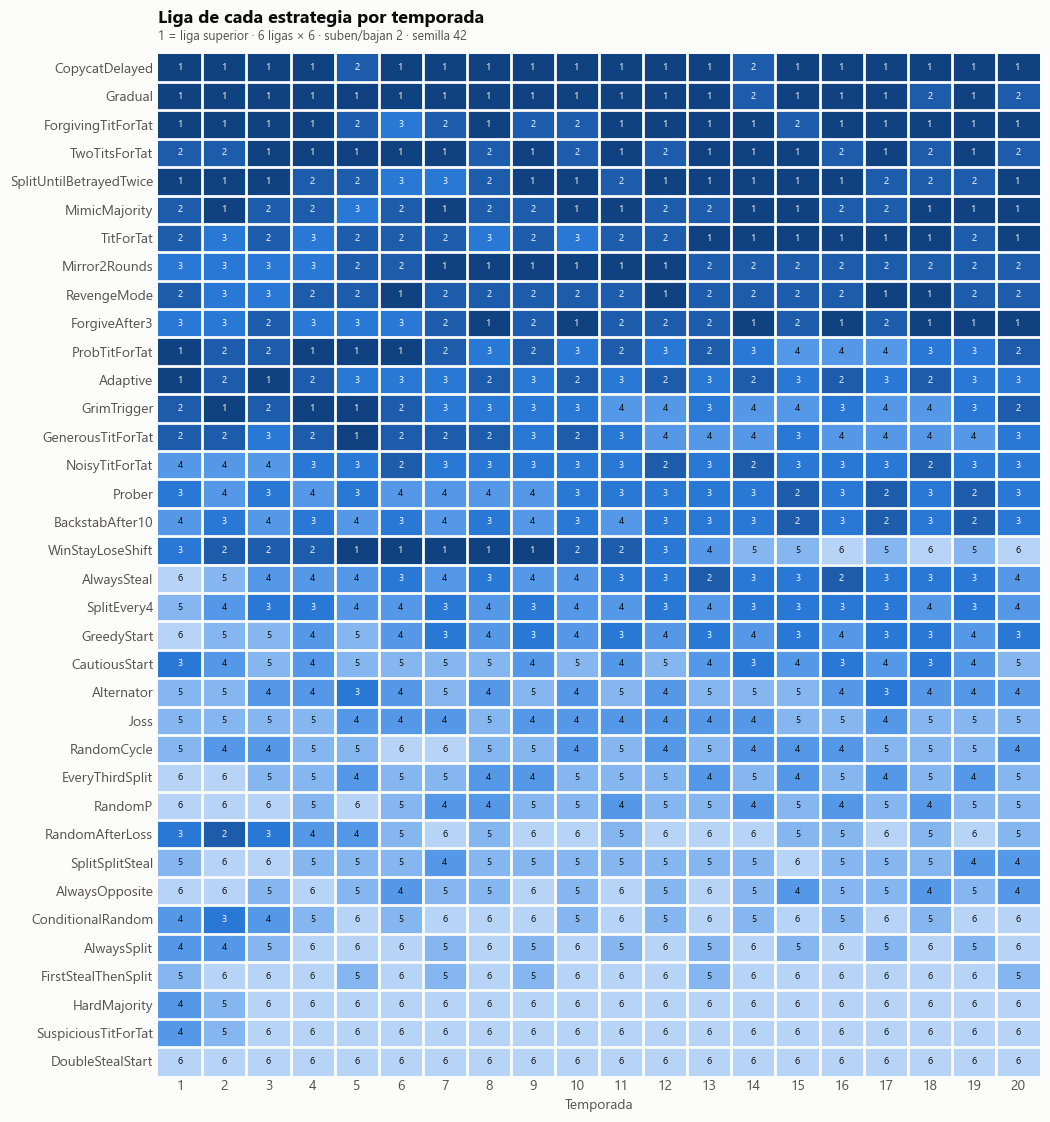

In [4]:
# El run canónico, temporada a temporada (un solo torneo, semilla 42)
fig = plots.plot_leagues_by_season(canon)
guardar(fig, "f02_canonico_ligas")

## 3. ¿Ganar cada partido es ganar el torneo?

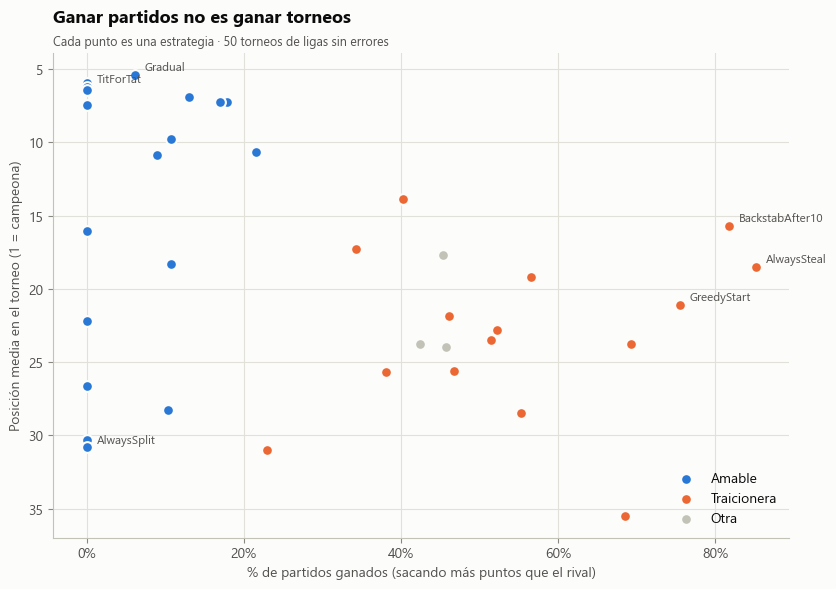

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 6))
for g, c in COLOR_GRUPO.items():
    d = r0[r0.grupo == g]
    ax.scatter(d.win_rate, d.rank_mean, s=60, color=c, edgecolor=SURFACE, linewidth=1.5,
               label=g, zorder=3)
for n in ["AlwaysSteal", "TitForTat", "Gradual", "AlwaysSplit", "BackstabAfter10", "GreedyStart"]:
    row = r0[r0.strategy == n].iloc[0]
    ax.annotate(n, (row.win_rate, row.rank_mean), xytext=(7, 3), textcoords="offset points",
                fontsize=8.5, color=INK_2)
ax.invert_yaxis()
_percent_axis(ax.xaxis)
ax.set_xlabel("% de partidos ganados (sacando más puntos que el rival)")
ax.set_ylabel("Posición media en el torneo (1 = campeona)")
ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Ganar partidos no es ganar torneos", pad=22)
_subtitle(ax, "Cada punto es una estrategia · 50 torneos de ligas sin errores")
fig.tight_layout(); guardar(fig, "f04_ganar_partidos")

als = r0[r0.strategy == "AlwaysSteal"].iloc[0]; tft = r0[r0.strategy == "TitForTat"].iloc[0]
CIFRAS["alwayssteal_win_rate"] = round(als.win_rate * 100)
CIFRAS["alwayssteal_rank"] = round(als.rank_mean, 1)
CIFRAS["tft_win_rate"] = round(tft.win_rate * 100)
CIFRAS["tft_rank"] = round(tft.rank_mean, 1)

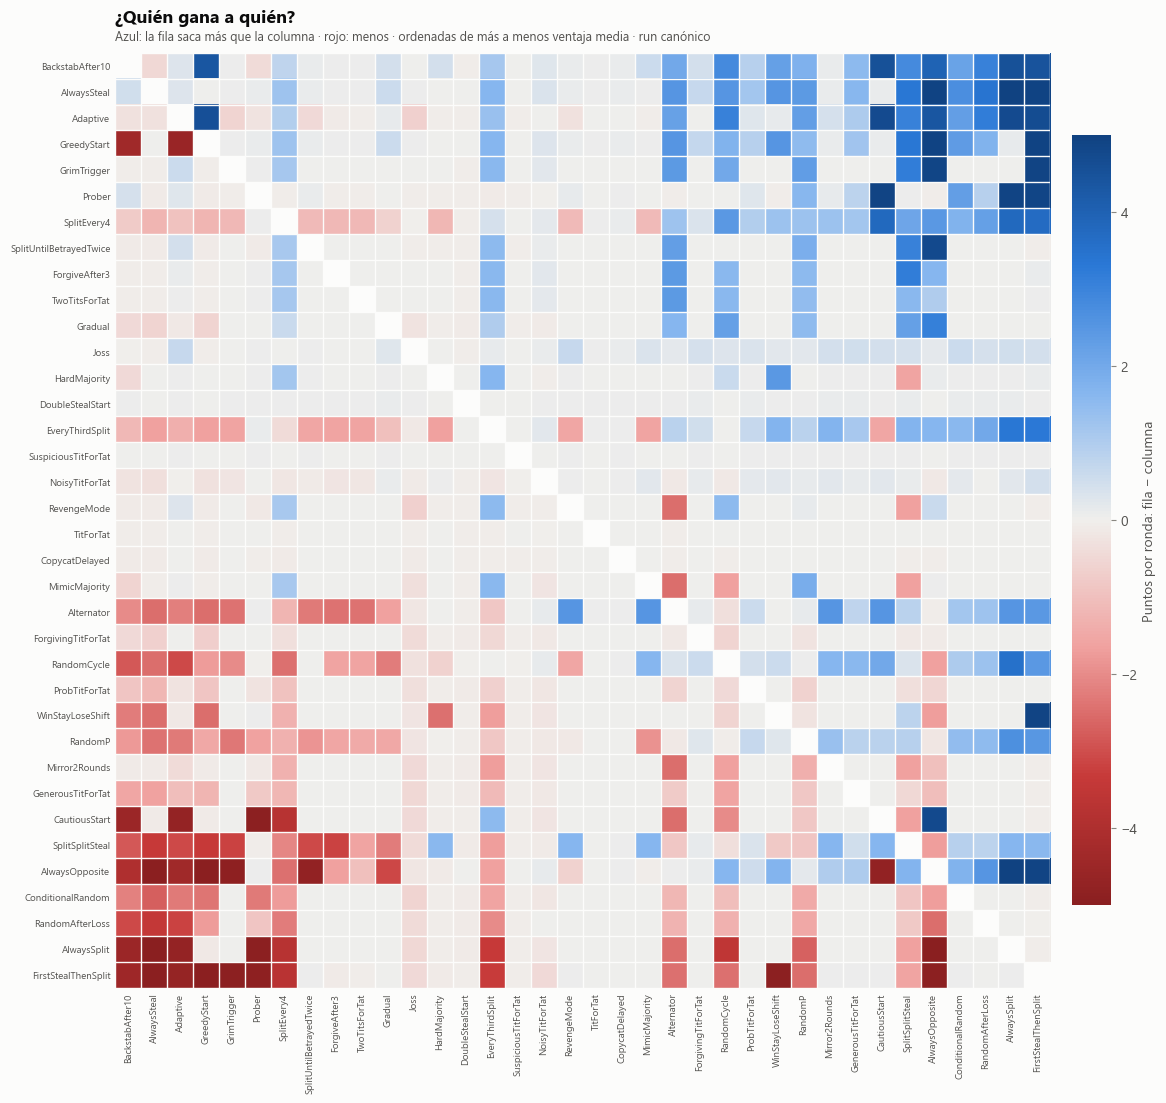

{'gana': 31, 'empata': 4, 'pierde': 0}

In [6]:
fig = plots.plot_head_to_head(canon.matches, title_note="run canónico")
guardar(fig, "f05_heatmap")
from split_steal.analysis import head_to_head
h = head_to_head(canon.matches)
row = h.loc["AlwaysSteal"].drop("AlwaysSteal").dropna()
CIFRAS["alwayssteal_h2h"] = {"gana": int((row > 0).sum()), "empata": int((row == 0).sum()),
                            "pierde": int((row < 0).sum())}
CIFRAS["alwayssteal_h2h"]

## 4. ¿Qué tienen en común las ganadoras? Las 4 cualidades de Axelrod

Axelrod resumió las estrategias ganadoras en 4 rasgos: **amable** (no traiciona primero),
**responde** (castiga una traición), **perdona** (vuelve a cooperar) y **clara** (predecible).
Los medimos con nuestras etiquetas y estadísticas.

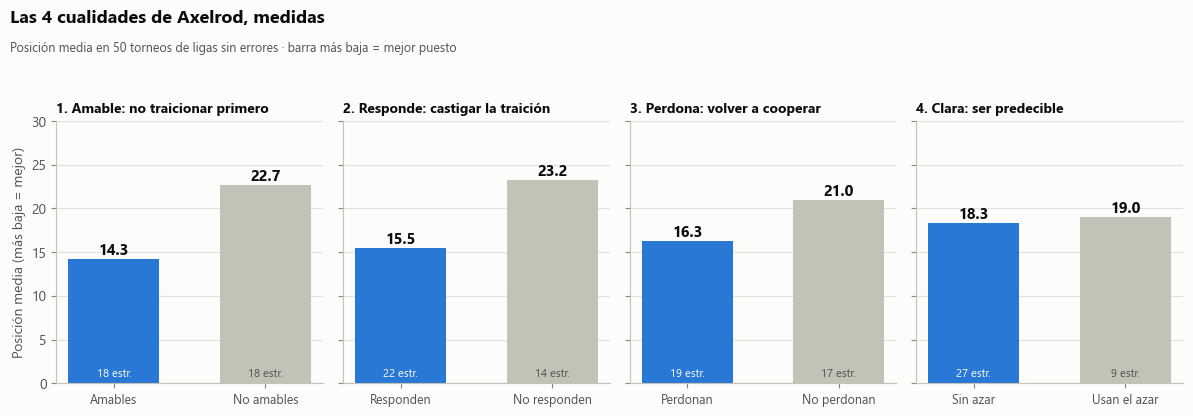

({'Amables': [np.float64(14.3), np.float64(22.7)],
  'Responden': [np.float64(15.5), np.float64(23.2)],
  'Perdonan': [np.float64(16.3), np.float64(21.0)],
  'Sin azar': [np.float64(18.3), np.float64(19.0)]},
 [np.float64(11.6), np.float64(27.8)])

In [7]:
def tiene(tag):
    return r0.strategy.map(lambda n: tag in make_strategy(n).tags)

CUALIDADES = [  # (título, máscara "con la cualidad", etiqueta con, etiqueta sin)
    ("1. Amable: no traicionar primero", tiene("amable"), "Amables", "No amables"),
    ("2. Responde: castigar la traición", tiene("vengativa"), "Responden", "No responden"),
    ("3. Perdona: volver a cooperar", tiene("perdona"), "Perdonan", "No perdonan"),
    ("4. Clara: ser predecible", ~tiene("aleatoria"), "Sin azar", "Usan el azar"),
]
fig, axes = plt.subplots(1, 4, figsize=(12, 4.2), sharey=True)
for ax, (titulo, mask, con, sin) in zip(axes, CUALIDADES):
    vals = [r0[mask].rank_mean.mean(), r0[~mask].rank_mean.mean()]
    ax.bar([0, 1], vals, color=[SERIES[0], OTHERS_COLOR], width=0.6)
    for x, v, n in zip([0, 1], vals, [mask.sum(), (~mask).sum()]):
        ax.text(x, v + 0.5, f"{v:.1f}", ha="center", fontsize=11, color=INK, fontweight="bold")
        ax.text(x, 0.8, f"{n} estr.", ha="center", fontsize=8, color=SURFACE if x == 0 else INK_2)
    ax.set_xticks([0, 1], [con, sin], fontsize=9)
    ax.set_title(titulo, fontsize=10, loc="left")
    ax.set_ylim(0, 30)
    ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
axes[0].set_ylabel("Posición media (más baja = mejor)")
fig.suptitle("Las 4 cualidades de Axelrod, medidas", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.88, "Posición media en 50 torneos de ligas sin errores · barra más baja = mejor puesto",
         color=INK_2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.87)); guardar(fig, "f06_cualidades")

CIFRAS["cualidades"] = {sin.split()[-1] if False else con: [round(r0[m].rank_mean.mean(), 1), round(r0[~m].rank_mean.mean(), 1)]
                        for _, m, con, sin in CUALIDADES}
am = tiene("amable")
CIFRAS["amables_vengativas"] = [round(r0[am & tiene("vengativa")].rank_mean.mean(), 1),
                                round(r0[am & ~tiene("vengativa")].rank_mean.mean(), 1)]
CIFRAS["amables_no_vengativas"] = r0[am & ~tiene("vengativa")].strategy.tolist()
CIFRAS["rank_amables"] = round(r0[am].rank_mean.mean(), 1)
CIFRAS["rank_no_amables"] = round(r0[~am].rank_mean.mean(), 1)
CIFRAS["alwayssplit_rank"] = round(r0[r0.strategy == "AlwaysSplit"].rank_mean.item(), 1)
CIFRAS["cualidades"], CIFRAS["amables_vengativas"]

## 5. ¿Depende de con quién te juntes? (experiments/entornos.toml)

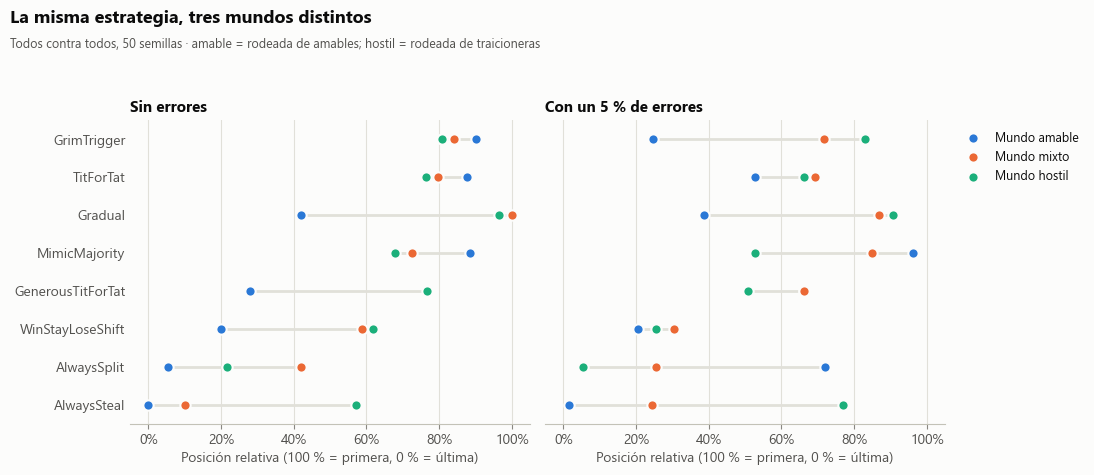

noise               0.00                0.05             
variant_group     amable hostil mixto amable hostil mixto
strategy                                                 
AlwaysSplit         18.0   17.4  21.3    6.0   20.9  27.1
AlwaysSteal         19.0   10.0  32.4   18.7    5.8  27.5
GenerousTitForTat   14.0    5.9   9.1    7.1   11.3  12.8
Gradual             11.4    1.8   1.0   12.0    3.0   5.7
GrimTrigger          2.8    5.0   6.5   14.6    4.6  10.9
MimicMajority        3.1    7.8  10.6    1.7   10.9   6.3
TitForTat            3.2    6.0   8.1    9.5    8.1  11.8
WinStayLoseShift    15.4    9.0  15.4   15.3   16.6  25.4

In [8]:
PROBES = ["TitForTat", "GenerousTitForTat", "Gradual", "MimicMajority", "GrimTrigger",
          "WinStayLoseShift", "AlwaysSplit", "AlwaysSteal"]
e = summ["entornos"].copy()
e["n"] = e.groupby("variant").strategy.transform("count")
e["percentil"] = 1 - (e.rank_mean - 1) / (e.n - 1)       # 100 % = primera, 0 % = última
e["mundo"] = e.variant_group.map({"amable": "Mundo amable", "mixto": "Mundo mixto",
                                  "hostil": "Mundo hostil"})
p = e[e.strategy.isin(PROBES)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
mundos = ["Mundo amable", "Mundo mixto", "Mundo hostil"]
orden = (p[p.noise == 0].groupby("strategy").percentil.mean().sort_values(ascending=False).index)
ypos = {s: i for i, s in enumerate(orden)}
for ax, noise, titulo in [(axes[0], 0.0, "Sin errores"), (axes[1], 0.05, "Con un 5 % de errores")]:
    d = p[p.noise == noise]
    for s in orden:
        v = d[d.strategy == s].percentil
        ax.plot([v.min(), v.max()], [ypos[s]] * 2, color=GRID, linewidth=2, zorder=1)
    for c, m in zip(SERIES, mundos):
        dm = d[d.mundo == m]
        ax.scatter(dm.percentil, dm.strategy.map(ypos), s=55, color=c, label=m,
                   edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.set_title(titulo, fontsize=11, loc="left")
    ax.set_xlim(-0.05, 1.05); _percent_axis(ax.xaxis)
    ax.set_xlabel("Posición relativa (100 % = primera, 0 % = última)")
    ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
axes[0].set_yticks(range(len(orden)), orden); axes[0].set_ylim(len(orden) - 0.5, -0.5)
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
fig.suptitle("La misma estrategia, tres mundos distintos", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.9, "Todos contra todos, 50 semillas · amable = rodeada de amables; hostil = rodeada de traicioneras",
         color=INK_2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.89)); guardar(fig, "f07_entornos")

tabla = p.pivot_table(index="strategy", columns=["noise", "variant_group"], values="rank_mean")
CIFRAS["entornos"] = {f"{s}|{n}|{g}": round(v, 1) for (n, g), col in tabla.items() for s, v in col.items()}
CIFRAS["entornos_n"] = e.groupby("variant_group").n.first().to_dict()
tabla.round(1)

## 6. ¿Qué pasa cuando hay malentendidos? (ruido)

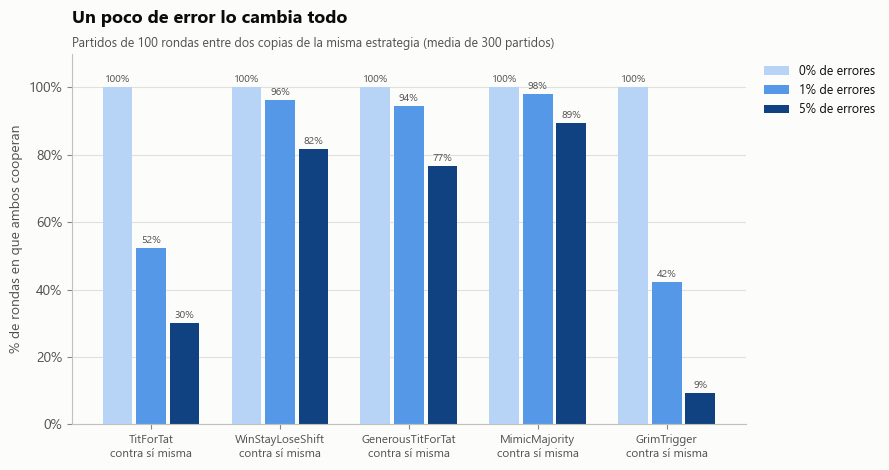

ruido,0.00,0.01,0.05
estrategia,,,
GenerousTitForTat,1.0,0.94,0.77
GrimTrigger,1.0,0.42,0.09
MimicMajority,1.0,0.98,0.89
TitForTat,1.0,0.52,0.30
WinStayLoseShift,1.0,0.96,0.82


In [9]:
PAREJAS = ["TitForTat", "WinStayLoseShift", "GenerousTitForTat", "MimicMajority", "GrimTrigger"]
RUIDOS = [0.0, 0.01, 0.05]
filas = []
for s in PAREJAS:
    for noise in RUIDOS:
        ms = [play_match(make_strategy(s), make_strategy(s), rounds=100, seed=k, noise=noise)
              for k in range(300)]
        filas.append({"estrategia": s, "ruido": noise,
                      "coop_mutua": np.mean([m.cc for m in ms]) / 100,
                      "puntos": np.mean([m.pa + m.pb for m in ms]) / 200})
par = pd.DataFrame(filas)

RAMPA = ["#b7d3f6", "#5598e7", "#104281"]   # claro -> oscuro = más ruido (escala ordinal)
fig, ax = plt.subplots(figsize=(9, 4.8))
w = 0.26
for k, (noise, c) in enumerate(zip(RUIDOS, RAMPA)):
    d = par[par.ruido == noise].set_index("estrategia").loc[PAREJAS]
    xs = np.arange(len(PAREJAS)) + (k - 1) * w
    ax.bar(xs, d.coop_mutua, width=w - 0.03, color=c, label=f"{noise:.0%} de errores")
    for x, v in zip(xs, d.coop_mutua):
        ax.text(x, v + 0.015, f"{v:.0%}", ha="center", fontsize=7.5, color=INK_2)
ax.set_xticks(range(len(PAREJAS)), [f"{s}\ncontra sí misma" for s in PAREJAS], fontsize=8.5)
ax.set_ylim(0, 1.1); _percent_axis(ax.yaxis)
ax.set_ylabel("% de rondas en que ambos cooperan")
ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
ax.set_title("Un poco de error lo cambia todo", pad=22)
_subtitle(ax, "Partidos de 100 rondas entre dos copias de la misma estrategia (media de 300 partidos)")
fig.tight_layout(); guardar(fig, "f08_ruido_parejas")
CIFRAS["parejas"] = {f"{r.estrategia}|{r.ruido}": round(r.coop_mutua * 100) for r in par.itertuples()}
par.pivot_table(index="estrategia", columns="ruido", values="coop_mutua").round(2)

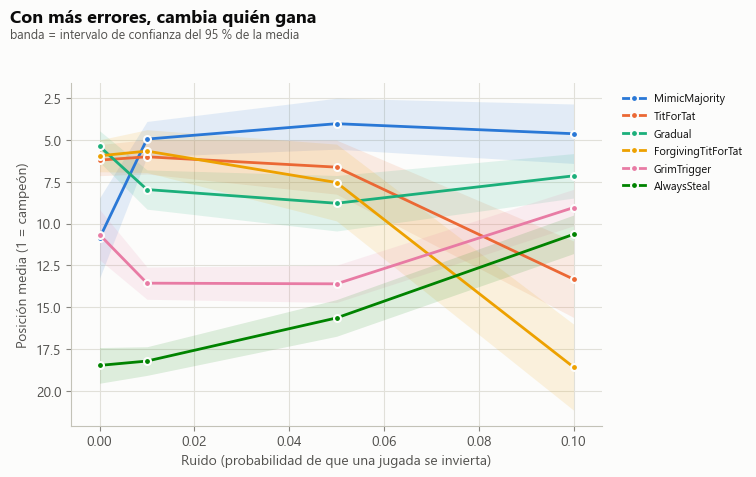

In [10]:
fig = plots.plot_sweep(summ["ruido"], x="noise", metric="rank_mean",
                       strategies=["MimicMajority", "TitForTat", "Gradual", "ForgivingTitForTat",
                                   "GrimTrigger", "AlwaysSteal"],
                       title="Con más errores, cambia quién gana")
guardar(fig, "f09_ruido_torneo")
rr = summ["ruido"]
coop = rr.groupby("noise").coop_rate.mean()
CIFRAS["coop_media_por_ruido"] = {str(k): round(v * 100) for k, v in coop.items()}
CIFRAS["ruido_rank"] = {f"{r.strategy}|{r.noise}": round(r.rank_mean, 1) for r in rr.itertuples()
                        if r.strategy in ["MimicMajority", "TitForTat", "AlwaysSteal", "GrimTrigger",
                                          "Gradual", "ForgivingTitForTat", "GenerousTitForTat"]}
CIFRAS["mimic_titulos_ruido5"] = round(rr[(rr.strategy == "MimicMajority") & (rr.noise == 0.05)].title_rate.item() * 100)

## 7. ¿Cuándo conviene perdonar?

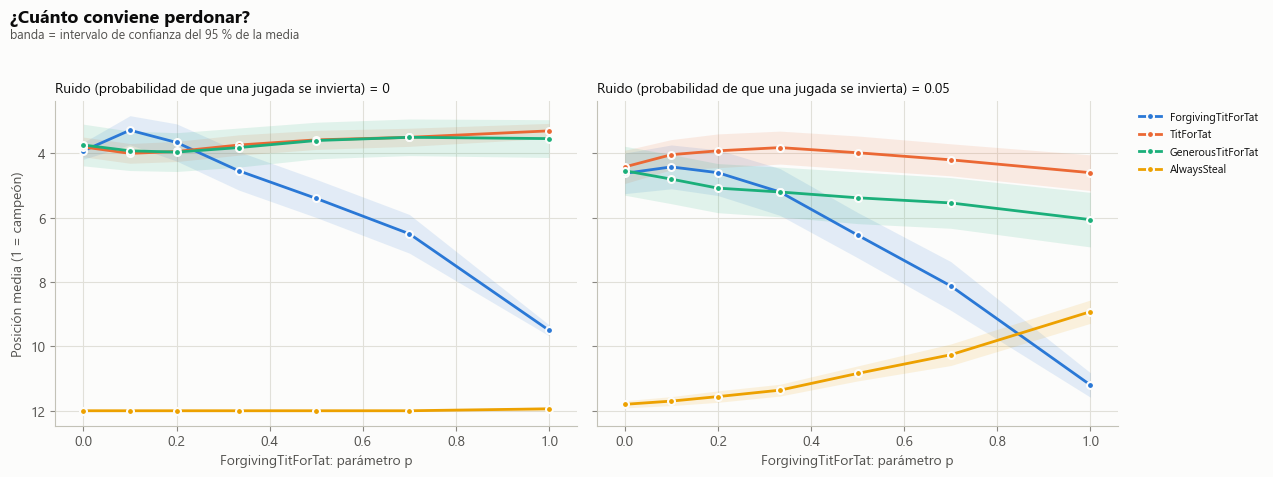

,p,noise,rank_mean,rank_ci95,points_per_round
4,0.00,0.00,3.92,0.26,2.68
15,0.00,0.05,4.62,0.63,2.28
25,0.10,0.00,3.28,0.45,2.71
38,0.10,0.05,4.42,0.68,2.31
50,0.20,0.00,3.66,0.58,2.69
62,0.20,0.05,4.60,0.71,2.32
76,0.33,0.00,4.54,0.60,2.65
87,0.33,0.05,5.20,0.73,2.31
101,0.50,0.00,5.40,0.59,2.60
115,0.50,0.05,6.54,0.70,2.26


In [11]:
fig = plots.plot_sweep(summ["perdon_optimo"], x="ForgivingTitForTat.p", facet="noise",
                       strategies=["ForgivingTitForTat", "TitForTat", "GenerousTitForTat", "AlwaysSteal"],
                       title="¿Cuánto conviene perdonar?")
guardar(fig, "f10_perdon")
po = summ["perdon_optimo"].rename(columns={"ForgivingTitForTat.p": "p"}); f = po[po.strategy == "ForgivingTitForTat"]
CIFRAS["perdon"] = {f"{r.p}|{r.noise}": round(r.rank_mean, 1) for r in f.itertuples()}
best = f.loc[f.groupby("noise").rank_mean.idxmin()]
CIFRAS["perdon_mejor_p"] = {str(r.noise): r.p for r in best.itertuples()}
a = po[po.strategy == "AlwaysSteal"]
CIFRAS["alwayssteal_segun_perdon_ruido5"] = {str(r.p): round(r.rank_mean, 1) for r in a[a.noise == 0.05].itertuples()}
f[["p", "noise", "rank_mean", "rank_ci95", "points_per_round"]]

## 8. ¿Juzgar por el último gesto o por la trayectoria?

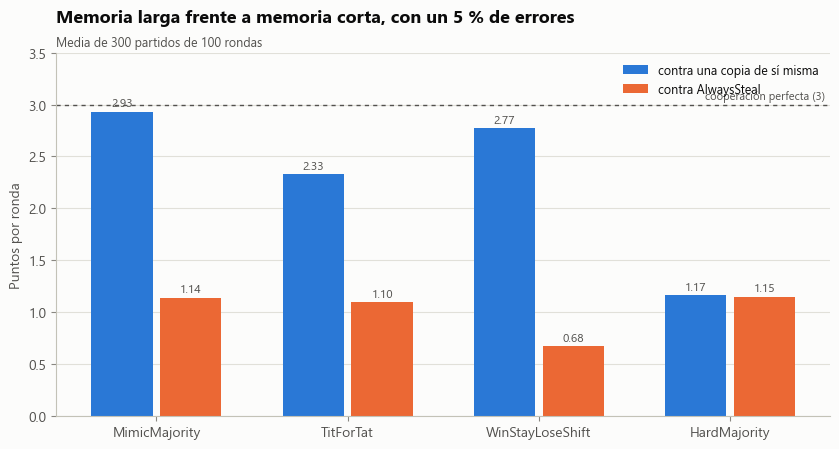

rival,AlwaysSteal,misma
estrategia,,
HardMajority,1.15,1.17
MimicMajority,1.14,2.93
TitForTat,1.10,2.33
WinStayLoseShift,0.68,2.77


In [12]:
ESTRAT = ["MimicMajority", "TitForTat", "WinStayLoseShift", "HardMajority"]
filas = []
for s in ESTRAT:
    for rival in ["misma", "AlwaysSteal"]:
        ms = [play_match(make_strategy(s), make_strategy(s if rival == "misma" else rival),
                         rounds=100, seed=k, noise=0.05) for k in range(300)]
        filas.append({"estrategia": s, "rival": rival, "puntos": np.mean([m.pa for m in ms]) / 100})
mem = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(8.5, 4.6))
w = 0.36
for k, (rival, c, lab) in enumerate([("misma", SERIES[0], "contra una copia de sí misma"),
                                     ("AlwaysSteal", SERIES[1], "contra AlwaysSteal")]):
    d = mem[mem.rival == rival].set_index("estrategia").loc[ESTRAT]
    xs = np.arange(len(ESTRAT)) + (k - 0.5) * w
    ax.bar(xs, d.puntos, width=w - 0.04, color=c, label=lab)
    for x, v in zip(xs, d.puntos):
        ax.text(x, v + 0.05, f"{v:.2f}", ha="center", fontsize=8.5, color=INK_2)
ax.axhline(3, color=INK_2, linewidth=1, linestyle=(0, (3, 3)))
ax.text(len(ESTRAT) - 0.5, 3.05, "cooperación perfecta (3)", ha="right", fontsize=8, color=INK_2)
ax.set_xticks(range(len(ESTRAT)), ESTRAT)
ax.set_ylim(0, 3.5); ax.set_ylabel("Puntos por ronda")
ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.set_title("Memoria larga frente a memoria corta, con un 5 % de errores", pad=22)
_subtitle(ax, "Media de 300 partidos de 100 rondas")
fig.tight_layout(); guardar(fig, "f11_memoria")
CIFRAS["memoria"] = {f"{r.estrategia}|{r.rival}": round(r.puntos, 2) for r in mem.itertuples()}
mem.pivot_table(index="estrategia", columns="rival", values="puntos").round(2)

## 9. ¿Liga o todos contra todos?

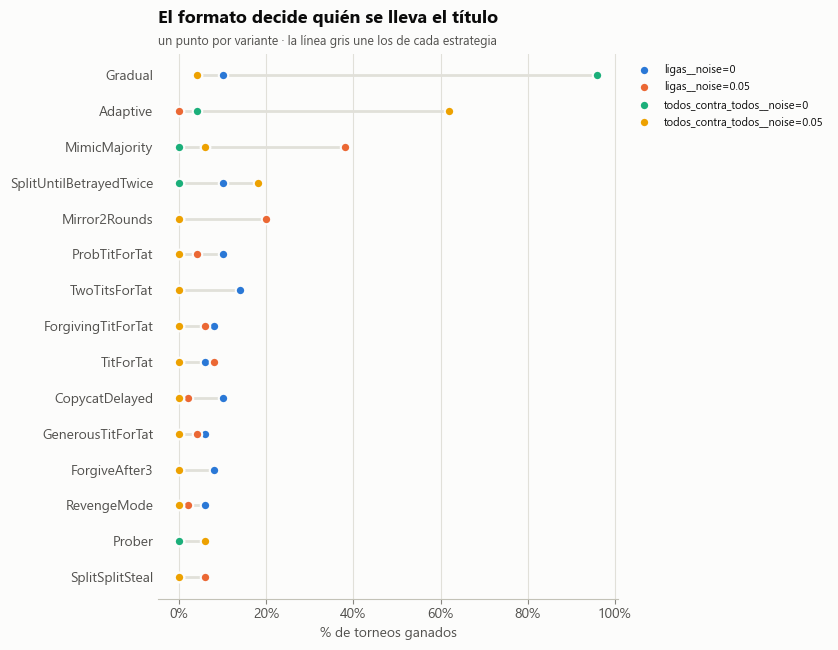

({'ligas__noise=0': ['TwoTitsForTat', 14],
  'ligas__noise=0.05': ['MimicMajority', 38],
  'todos_contra_todos__noise=0': ['Gradual', 96],
  'todos_contra_todos__noise=0.05': ['Adaptive', 62]},
 {'ligas__noise=0': 13,
  'ligas__noise=0.05': 13,
  'todos_contra_todos__noise=0': 2,
  'todos_contra_todos__noise=0.05': 7})

In [13]:
fig = plots.plot_variants(summ["formatos"], metric="title_rate",
                          title="El formato decide quién se lleva el título")
guardar(fig, "f12_formatos")
fo = summ["formatos"]
CIFRAS["formatos_max_titulos"] = {v: [g.loc[g.title_rate.idxmax(), "strategy"], round(g.title_rate.max() * 100)]
                                  for v, g in fo.groupby("variant")}
CIFRAS["formatos_campeones_distintos"] = {v: int((g.title_rate > 0).sum()) for v, g in fo.groupby("variant")}
CIFRAS["formatos_max_titulos"], CIFRAS["formatos_campeones_distintos"]

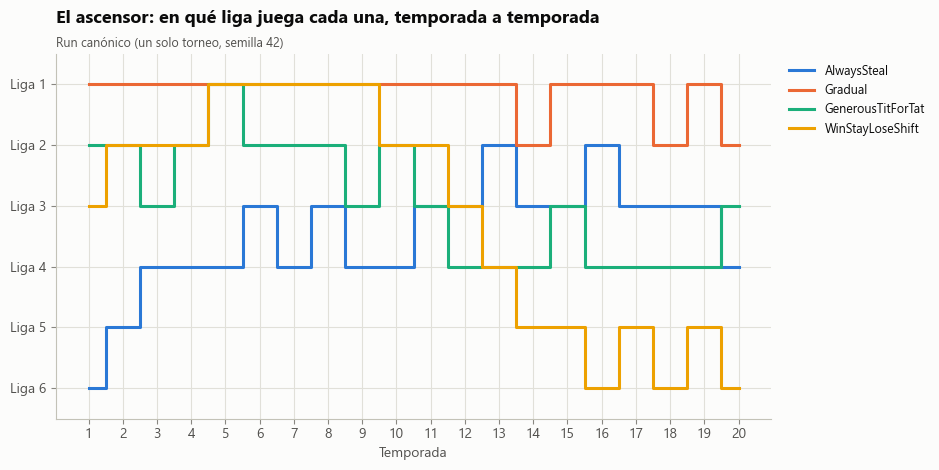

In [14]:
st = canon.standings[canon.standings.season > 0]
SEGUIR = ["AlwaysSteal", "Gradual", "GenerousTitForTat", "WinStayLoseShift"]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for c, n in zip(SERIES, SEGUIR):
    d = st[st.name == n].sort_values("season")
    ax.step(d.season, d.league, where="mid", color=c, linewidth=2.2, label=n)
ax.set_yticks(range(1, 7), [f"Liga {i}" for i in range(1, 7)]); ax.set_ylim(6.5, 0.5)
ax.set_xticks(range(1, 21)); ax.set_xlabel("Temporada")
ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
ax.set_title("El ascensor: en qué liga juega cada una, temporada a temporada", pad=22)
_subtitle(ax, "Run canónico (un solo torneo, semilla 42)")
fig.tight_layout(); guardar(fig, "f13_ascensor")
CIFRAS["trayectoria_alwayssteal"] = st[st.name == "AlwaysSteal"].sort_values("season").league.tolist()

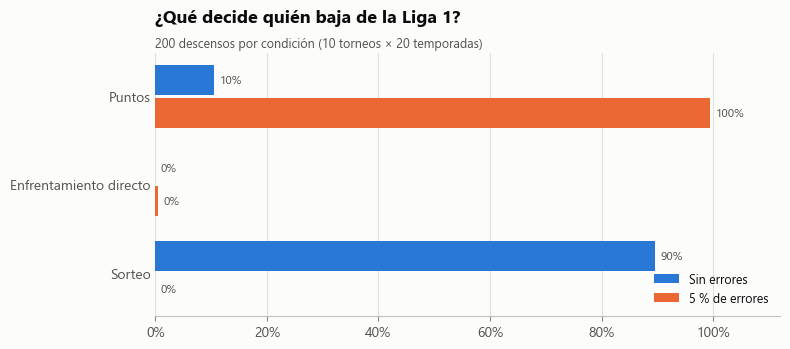

ruido,0.00,0.05
criterio,,
points,0.1,9.95e-01
head_to_head,0.0,5.00e-03
draw,0.9,0.00e+00


In [15]:
# ¿Qué criterio decide los descensos de la Liga 1? 10 semillas con y sin ruido.
filas = []
for noise in [0.0, 0.05]:
    multi = run_seeds(TournamentConfig(noise=noise), n_seeds=10)
    s = multi.standings
    frontera = s[(s.season > 0) & (s.league == 1) & (s.position == 4)]
    for crit, n in frontera.decided_by.value_counts(normalize=True).items():
        filas.append({"ruido": noise, "criterio": crit, "pct": n})
sorteo = pd.DataFrame(filas)
NOMBRES = {"points": "Puntos", "head_to_head": "Enfrentamiento directo",
           "point_diff": "Diferencia de puntos", "draw": "Sorteo"}
tabla_s = sorteo.pivot_table(index="criterio", columns="ruido", values="pct", fill_value=0)
tabla_s = tabla_s.reindex([k for k in NOMBRES if k in tabla_s.index])

fig, ax = plt.subplots(figsize=(8, 3.6))
w = 0.38
for k, (noise, c, lab) in enumerate([(0.0, SERIES[0], "Sin errores"), (0.05, SERIES[1], "5 % de errores")]):
    vals = tabla_s[noise] if noise in tabla_s else pd.Series(0, index=tabla_s.index)
    ys = np.arange(len(tabla_s)) + (k - 0.5) * w
    ax.barh(ys, vals, height=w - 0.04, color=c, label=lab)
    for yv, v in zip(ys, vals):
        ax.text(v + 0.01, yv, f"{v:.0%}", va="center", fontsize=8.5, color=INK_2)
ax.set_yticks(range(len(tabla_s)), [NOMBRES[k] for k in tabla_s.index]); ax.invert_yaxis()
ax.set_xlim(0, 1.12); _percent_axis(ax.xaxis)
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.set_title("¿Qué decide quién baja de la Liga 1?", pad=22)
_subtitle(ax, "200 descensos por condición (10 torneos × 20 temporadas)")
fig.tight_layout(); guardar(fig, "f14_sorteo")
CIFRAS["sorteo_liga1"] = {str(k): round(v * 100) for k, v in (tabla_s.loc["draw"] if "draw" in tabla_s.index else pd.Series(dtype=float)).items()}
tabla_s

## 10. ¿Y si traicionar tienta más?

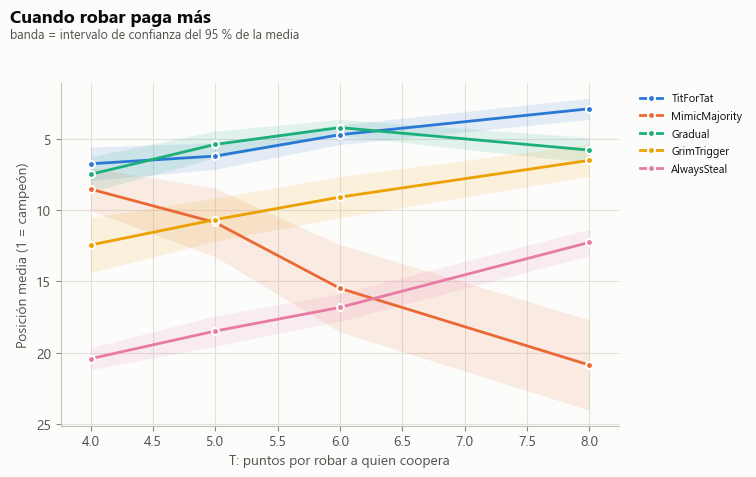

In [16]:
fig = plots.plot_sweep(summ["tentacion"], x="payoff.T", metric="rank_mean",
                       strategies=["TitForTat", "MimicMajority", "Gradual", "GrimTrigger", "AlwaysSteal"],
                       title="Cuando robar paga más")
guardar(fig, "f15_tentacion")
te = summ["tentacion"].rename(columns={"payoff.T": "T"})
CIFRAS["tentacion"] = {f"{r.strategy}|{r.T}": round(r.rank_mean, 1) for r in te.itertuples()
                       if r.strategy in ["TitForTat", "MimicMajority", "AlwaysSteal"]}

## 11. ¿Puede la cooperación conquistar un mundo egoísta? (evolución)

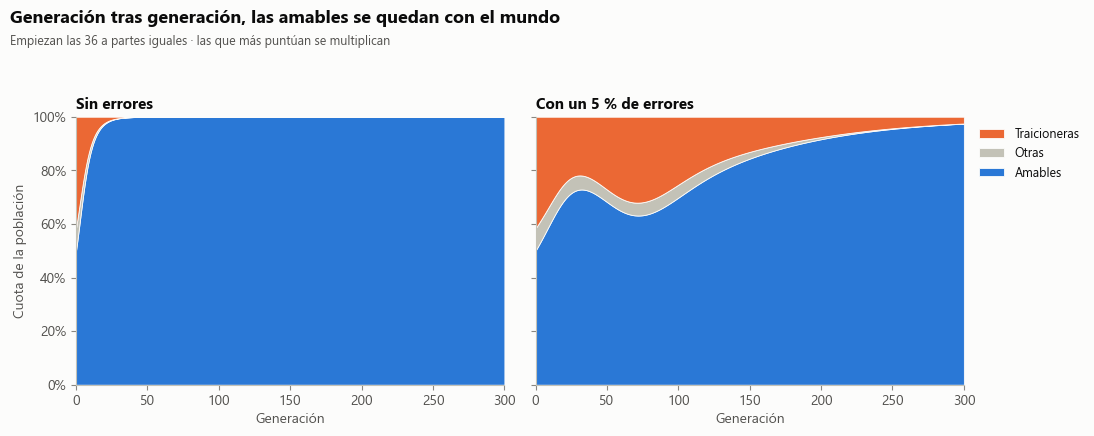

({'supervivientes': 18,
  'amables': np.float64(100.0),
  'top': {'Gradual': 9.9,
   'ForgivingTitForTat': 7.6,
   'ProbTitForTat': 7.6,
   'CopycatDelayed': 7.3,
   'TitForTat': 7.2}},
 {'supervivientes': 23,
  'amables': np.float64(97.4),
  'top': {'ProbTitForTat': 58.2,
   'ForgivingTitForTat': 14.8,
   'GenerousTitForTat': 12.6,
   'ConditionalRandom': 5.4,
   'RandomAfterLoss': 5.0}})

In [17]:
M0 = payoff_matrix(EvolutionConfig(noise=0.0))
M5 = payoff_matrix(EvolutionConfig(noise=0.05))
GEN = 300
ev0, ev5 = evolve(M0, None, GEN), evolve(M5, None, GEN)

def por_grupo(shares):
    return shares.T.groupby(shares.columns.map(grupo)).sum().T[["Amable", "Otra", "Traicionera"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, sh, titulo in [(axes[0], ev0, "Sin errores"), (axes[1], ev5, "Con un 5 % de errores")]:
    g = por_grupo(sh)
    ax.stackplot(g.index, [g[c] for c in g.columns], colors=[COLOR_GRUPO[c] for c in g.columns],
                 labels=[c + "s" for c in g.columns], edgecolor=SURFACE, linewidth=0.6)
    ax.set_xlim(0, GEN); ax.set_ylim(0, 1); _percent_axis(ax.yaxis)
    ax.set_title(titulo, fontsize=11, loc="left"); ax.set_xlabel("Generación")
axes[0].set_ylabel("Cuota de la población")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9, reverse=True)
fig.suptitle("Generación tras generación, las amables se quedan con el mundo", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.text(0.01, 0.9, "Empiezan las 36 a partes iguales · las que más puntúan se multiplican",
         color=INK_2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.89)); guardar(fig, "f16_evo_tipos")

def resumen(sh):
    fin = sh.iloc[-1]
    return {"supervivientes": int((fin > 0).sum()),
            "amables": round(por_grupo(sh).iloc[-1]["Amable"] * 100, 1),
            "top": {k: round(v * 100, 1) for k, v in fin.sort_values(ascending=False).head(5).items()}}
CIFRAS["evo_sin_ruido"], CIFRAS["evo_ruido5"] = resumen(ev0), resumen(ev5)
CIFRAS["evo_sin_ruido"], CIFRAS["evo_ruido5"]

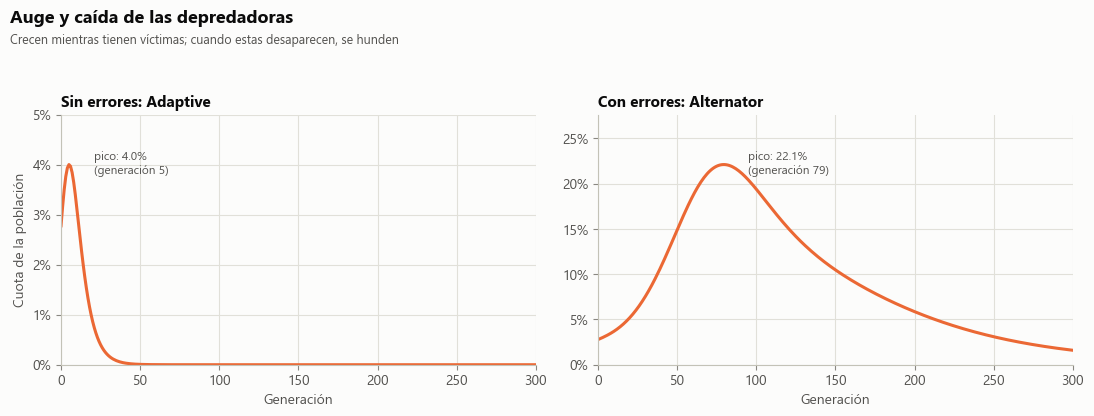

({'inicio': np.float64(2.8),
  'pico': np.float64(4.0),
  'gen_pico': 5,
  'final': np.float64(0.0),
  'extinta_gen': 119},
 {'inicio': np.float64(2.8),
  'pico': np.float64(22.1),
  'gen_pico': 79,
  'final': np.float64(1.6),
  'extinta_gen': None})

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, sh, n, titulo in [(axes[0], ev0, "Adaptive", "Sin errores: Adaptive"),
                          (axes[1], ev5, "Alternator", "Con errores: Alternator")]:
    ax.plot(sh.index, sh[n], color=SERIES[1], linewidth=2.2)
    pico = sh[n].idxmax()
    ax.annotate(f"pico: {sh[n].max():.1%}\n(generación {pico})", (pico, sh[n].max()),
                xytext=(18, -6), textcoords="offset points", fontsize=8.5, color=INK_2)
    ax.set_xlim(0, GEN); ax.set_ylim(0, sh[n].max() * 1.25); _percent_axis(ax.yaxis)
    ax.set_title(titulo, fontsize=11, loc="left"); ax.set_xlabel("Generación")
    ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True)
axes[0].set_ylabel("Cuota de la población")
fig.suptitle("Auge y caída de las depredadoras", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.9, "Crecen mientras tienen víctimas; cuando estas desaparecen, se hunden",
         color=INK_2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.89)); guardar(fig, "f17_evo_depredadoras")
def pico(sh, n):
    ext = sh.index[sh[n] == 0]
    return {"inicio": round(sh[n].iloc[0] * 100, 1), "pico": round(sh[n].max() * 100, 1),
            "gen_pico": int(sh[n].idxmax()), "final": round(sh[n].iloc[-1] * 100, 2),
            "extinta_gen": int(ext[0]) if len(ext) else None}
CIFRAS["depredadora_adaptive"], CIFRAS["depredadora_alternator"] = pico(ev0, "Adaptive"), pico(ev5, "Alternator")
CIFRAS["depredadora_adaptive"], CIFRAS["depredadora_alternator"]

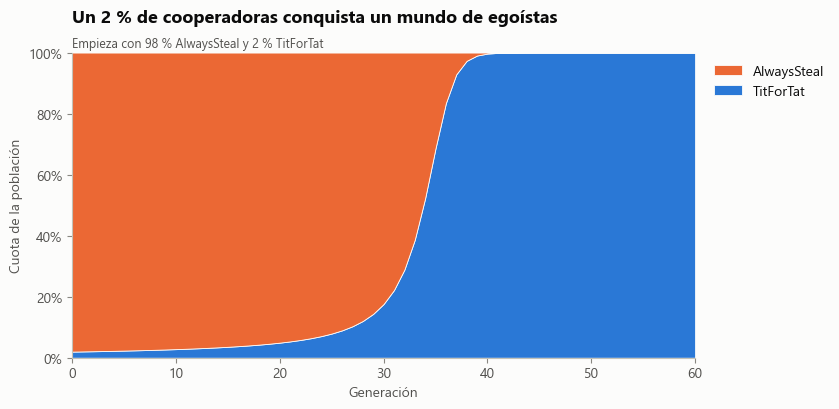

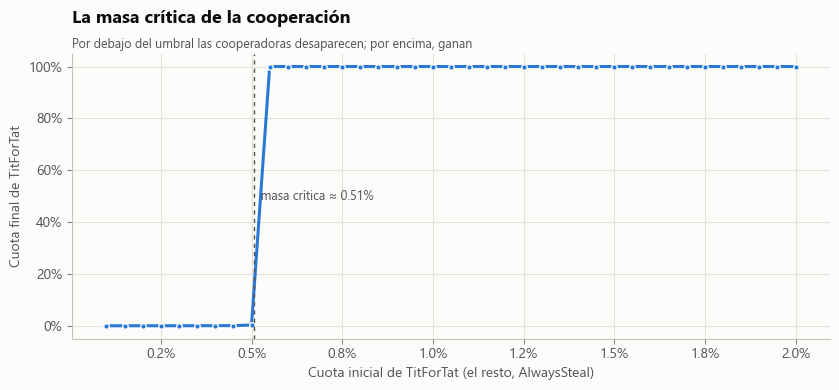

(np.float64(0.51), 34)

In [19]:
# Un mundo de egoístas con unos pocos TitForTat
M2 = payoff_matrix(EvolutionConfig(roster="AlwaysSteal, TitForTat"))
inv = evolve(M2, {"AlwaysSteal": 0.98, "TitForTat": 0.02}, 60)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.stackplot(inv.index, inv["TitForTat"], inv["AlwaysSteal"], colors=[SERIES[0], SERIES[1]],
             labels=["TitForTat", "AlwaysSteal"], edgecolor=SURFACE, linewidth=0.6)
ax.set_xlim(0, 60); ax.set_ylim(0, 1); _percent_axis(ax.yaxis)
ax.set_xlabel("Generación"); ax.set_ylabel("Cuota de la población")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, reverse=True)
ax.set_title("Un 2 % de cooperadoras conquista un mundo de egoístas", pad=22)
_subtitle(ax, "Empieza con 98 % AlwaysSteal y 2 % TitForTat")
fig.tight_layout(); guardar(fig, "f18_evo_invasion")
CIFRAS["invasion_gen_50pct"] = int((inv["TitForTat"] >= 0.5).idxmax())
CIFRAS["invasion_gen_99pct"] = int((inv["TitForTat"] >= 0.99).idxmax())

# Masa crítica: ¿desde qué cuota inicial gana TitForTat?
# Con x = cuota de TitForTat, TitForTat gana más que AlwaysSteal cuando
#   x·M[T,T] + (1-x)·M[T,A]  >  x·M[A,T] + (1-x)·M[A,A]
# y despejando x sale el umbral (por nombre, no por posición en la matriz):
T, A = "TitForTat", "AlwaysSteal"
umbral = (M2.loc[A, A] - M2.loc[T, A]) / ((M2.loc[T, T] - M2.loc[A, T]) + (M2.loc[A, A] - M2.loc[T, A]))
iniciales = np.round(np.linspace(0.001, 0.02, 39), 4)
finales = [evolve(M2, {"AlwaysSteal": 1 - x, "TitForTat": x}, 400)["TitForTat"].iloc[-1] for x in iniciales]
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(iniciales, finales, color=SERIES[0], linewidth=2.2, marker="o", markersize=4,
        markeredgecolor=SURFACE)
ax.axvline(umbral, color=INK_2, linewidth=1, linestyle=(0, (3, 3)))
ax.text(umbral, 0.5, f"  masa crítica ≈ {umbral:.2%}", color=INK_2, fontsize=9, va="center")
from matplotlib.ticker import PercentFormatter
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=1)); _percent_axis(ax.yaxis)
ax.set_xlabel("Cuota inicial de TitForTat (el resto, AlwaysSteal)")
ax.set_ylabel("Cuota final de TitForTat")
ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_title("La masa crítica de la cooperación", pad=22)
_subtitle(ax, "Por debajo del umbral las cooperadoras desaparecen; por encima, ganan")
fig.tight_layout(); guardar(fig, "f19_masa_critica")
CIFRAS["masa_critica_pct"] = round(umbral * 100, 2)
CIFRAS["masa_critica_pct"], CIFRAS["invasion_gen_50pct"]

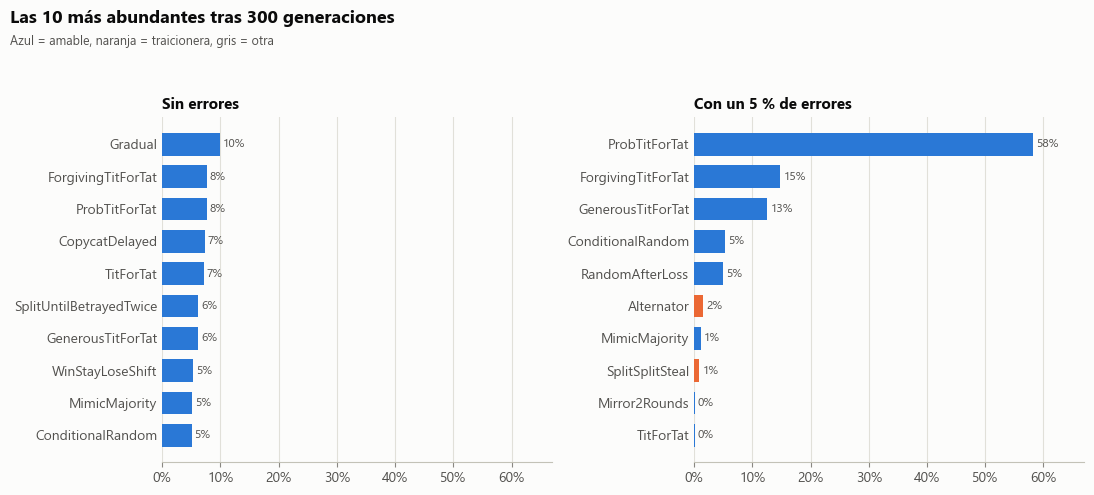

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True)
for ax, sh, titulo in [(axes[0], ev0, "Sin errores"), (axes[1], ev5, "Con un 5 % de errores")]:
    fin = sh.iloc[-1].sort_values(ascending=False).head(10)[::-1]
    ax.barh(fin.index, fin.values, color=[COLOR_GRUPO[grupo(n)] for n in fin.index], height=0.7)
    for yv, v in enumerate(fin.values):
        ax.text(v + 0.005, yv, f"{v:.0%}", va="center", fontsize=8.5, color=INK_2)
    _percent_axis(ax.xaxis); ax.set_title(titulo, fontsize=11, loc="left")
    ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
    ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
axes[0].set_xlim(0, ev5.iloc[-1].max() * 1.15)
fig.suptitle(f"Las 10 más abundantes tras {GEN} generaciones", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.text(0.01, 0.91, "Azul = amable, naranja = traicionera, gris = otra", color=INK_2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.9)); guardar(fig, "f20_evo_supervivientes")

## Guardar las cifras para el informe

In [21]:
def limpio(x):
    if isinstance(x, dict): return {str(k): limpio(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)): return [limpio(v) for v in x]
    if isinstance(x, (np.integer,)): return int(x)
    if isinstance(x, (np.floating,)): return float(x)
    if isinstance(x, (np.bool_,)): return bool(x)
    return x
(ROOT / "docs" / "informe" / "cifras.json").write_text(
    json.dumps(limpio(CIFRAS), indent=2, ensure_ascii=False) + "\n", encoding="utf-8", newline="\n")
print(len(CIFRAS), "cifras guardadas;", len(list(FIGS.glob("*.png"))), "gráficas en", FIGS)

39 cifras guardadas; 21 gráficas en ..\docs\informe\figs
